In [1]:

from pathlib import Path
import sys

import numpy as np
import librosa
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import preprocess_audio
from time_features import extract_time_features

sample_file = (
    PROJECT_ROOT
    / "data/raw/Actor_01/03-01-01-01-01-01-01.wav"
)

audio, sr = preprocess_audio(
    sample_file,
    normalize=False,
    trim=True,
)

features = extract_time_features(audio)

FRAME_LENGTH = 400
HOP_LENGTH = 160

# Time at the center of each frame
frame_times = (
    np.arange(len(features["zcr"])) * HOP_LENGTH
    + FRAME_LENGTH / 2
) / sr

print("Frames:", len(frame_times))
print("Audio duration:", len(audio) / sr)


Frames: 152
Audio duration: 1.536


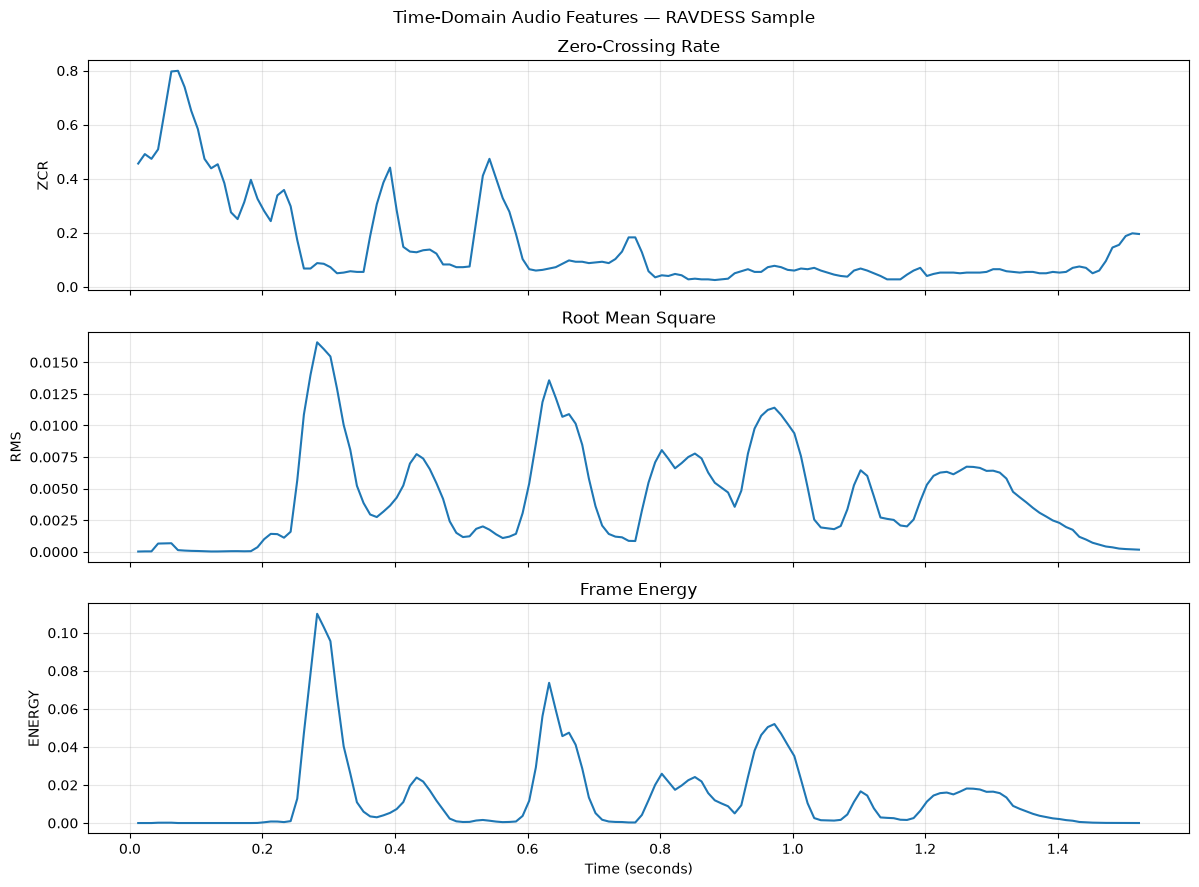

In [2]:

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

feature_info = [
    ("zcr", "Zero-Crossing Rate"),
    ("rms", "Root Mean Square"),
    ("energy", "Frame Energy"),
]

for ax, (feature_name, title) in zip(axes, feature_info):
    ax.plot(frame_times, features[feature_name])
    ax.set_title(title)
    ax.set_ylabel(feature_name.upper())
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle("Time-Domain Audio Features — RAVDESS Sample")
plt.tight_layout()
plt.show()


- Zero-Crossing Rate (ZCR)
In the first plot, ZCR is relatively high at the beginning, reaching approximately 0.8 around 0.07 seconds.
It then decreases, with a few additional peaks around 0.4 and 0.55 seconds.
This suggests that the early portions contain more rapid sign changes, potentially associated with unvoiced speech, consonants, or low-amplitude noise.
A high ZCR does not automatically mean a high-pitched voice or a particular emotion.

- Root Mean Square (RMS)
The second plot shows how the effective signal amplitude changes over time.
For example:
    - Around 0.28 seconds, RMS reaches approximately 0.016.
    - Around 0.63 seconds, another strong peak appears.
    - Toward the end, RMS gradually approaches zero.
These peaks correspond to relatively strong speech segments, while the valleys represent quieter portions or pauses.

- Frame Energy
The third plot follows almost exactly the same pattern as RMS.
This is expected because:
\[
E_t=400(RMS_t)^2
\]

For example, at an RMS of approximately 0.016:
\[
E=400(0.016)^2=0.1024
\]

That is close to the energy peak shown in your graph. This is a useful mathematical validation of your feature extraction implementation.

In [3]:
import pandas as pd
import numpy as np

feature_df = pd.read_csv(
    PROJECT_ROOT / "outputs/features/time_spectral_features.csv"
)

metadata_cols = [
    "sample_id",
    "trial_id",
    "actor_id",
    "emotion_label",
    "split",
]

feature_cols = [
    col for col in feature_df.columns
    if col not in metadata_cols
]

print("Dataset shape:", feature_df.shape)
print("Feature matrix shape:", feature_df[feature_cols].shape)

print("Missing values:", feature_df.isna().sum().sum())
print("Duplicate samples:", feature_df["sample_id"].duplicated().sum())

print("Split distribution:")
print(feature_df["split"].value_counts())

print("Feature summary:")
display(feature_df[feature_cols].describe().T.round(4))

Dataset shape: (1440, 33)
Feature matrix shape: (1440, 28)
Missing values: 0
Duplicate samples: 0
Split distribution:
split
train    960
test     240
val      240
Name: count, dtype: int64
Feature summary:


,count,mean,std,min,25%,50%,75%,max
zcr_mean,1440.0,0.1566,0.0392,0.0554,0.1293,0.1521,0.1814,0.3356
zcr_std,1440.0,0.1579,0.0423,0.0596,0.1268,0.1557,0.1858,0.2960
zcr_min,1440.0,0.0196,0.0129,0.0000,0.0125,0.0201,0.0276,0.0927
zcr_max,1440.0,0.6961,0.1093,0.3033,0.6184,0.7055,0.7794,0.9449
rms_mean,1440.0,0.0187,0.0229,0.0005,0.0052,0.0104,0.0215,0.1568
rms_std,1440.0,0.0163,0.0212,0.0005,0.0043,0.0088,0.0178,0.1430
rms_min,1440.0,0.0001,0.0003,0.0000,0.0000,0.0000,0.0001,0.0039
rms_max,1440.0,0.0702,0.0906,0.0018,0.0182,0.0375,0.0774,0.6911
energy_mean,1440.0,0.6353,1.7575,0.0003,0.0182,0.0744,0.3068,17.0695
energy_std,1440.0,0.9921,2.8215,0.0004,0.0261,0.1132,0.4519,30.2470


In [4]:
feature_std = feature_df[feature_cols].std()

print("Constant features:")
print(feature_std[feature_std == 0])

print("\nFeatures with the smallest standard deviations:")
display(feature_std.sort_values().head(10))

Constant features:
Series([], dtype: float64)

Features with the smallest standard deviations:


energy_min             0.000300
rms_min                0.000321
zcr_min                0.012851
spectral_energy_min    0.019220
rms_std                0.021173
rms_mean               0.022923
zcr_mean               0.039235
zcr_std                0.042287
rms_max                0.090593
zcr_max                0.109288
dtype: float64